# Models for understanding vaccination uptake

Use one shared workflow and a separate section for Logistic Regression, Random Forest and Histogram Gradient Boosting. Each section fits separate H1N1 and seasonal models on the same 20,364 respondents and uses the same three cross-validation folds. The full 5,341-person validation set stays separate; its results are now development evidence, not a fresh final test after repeated exploration.

This notebook starts from raw survey answers and reproduces notebook 04's **130 predictors**. Learned grouping/encoding happens inside each pipeline and CV fold. The agreed high-unknown training-row filter remains fixed; validation is not filtered. Doctor-recommendation missing rows are retained. No target is used as a predictor, and no test submission is generated.

Install the packages in `requirements-modeling.txt` in the notebook's Python environment. These pinned requirements were run with Python 3.9 in the project `.venv`; use a compatible Python 3.9–3.12 notebook kernel with those packages installed. Only pandas, NumPy, SciPy and scikit-learn are required; charts use SVG.

Interpretations describe associations and model behavior, not causal effects. Compare both targets separately; do not infer that the most predictive survey answer causes vaccination.


## 1. Shared imports, data and reproducible settings

The existing final files supply respondent IDs and labels only. Predictors are read from the original CSV, which prevents preprocessing learned before CV from entering fold evaluation. A DummyClassifier supplies a prevalence-only benchmark. ROC AUC is primary; average precision helps describe the imbalanced H1N1 target, and Brier score/log loss assess probability quality. Classification summaries use a fixed 0.5 threshold, not an optimized decision rule.


In [1]:
import os
# Limit native threads for predictable resource use, before importing numeric libraries.
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
from pathlib import Path
import json
import hashlib
import platform
import time
import warnings
from datetime import datetime, timezone
import numpy as np
import pandas as pd
try:
    import sklearn
    from sklearn.base import BaseEstimator, TransformerMixin, clone
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.model_selection import StratifiedKFold, cross_validate
    from sklearn.linear_model import LogisticRegression
    from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
    from sklearn.dummy import DummyClassifier
    from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                                 log_loss, balanced_accuracy_score, recall_score)
    from sklearn.exceptions import ConvergenceWarning
    from threadpoolctl import threadpool_limits
except ImportError as exc:
    raise ImportError('Install requirements-modeling.txt in this notebook kernel environment, then restart the kernel.') from exc
try:
    from IPython.display import display, SVG
except ImportError:
    def display(value):
        print(value.to_string() if hasattr(value, 'to_string') else value)
    SVG = None

ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p/'data_sets/training_set_features.csv').is_file()
             and (p/'data_processed/ml_features/train.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run preparation and feature-engineering notebooks first; start this notebook inside the project.')
OUT = ROOT/'reports/modeling'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
CV_FOLDS = 3
PERMUTATION_REPEATS = 3
RUN_STARTED = datetime.now(timezone.utc).isoformat()
raw_labeled = pd.read_csv(ROOT/'data_sets/training_set_features.csv').set_index('respondent_id')
label_source = pd.read_csv(ROOT/'data_sets/training_set_labels.csv').set_index('respondent_id')
prepared_train = pd.read_csv(ROOT/'data_processed/ml_features/train.csv')
prepared_validation = pd.read_csv(ROOT/'data_processed/ml_features/validation.csv')
feature_state = json.loads((ROOT/'data_processed/ml_features/preprocessing_state.json').read_text())
TARGETS = ['h1n1_vaccine', 'seasonal_vaccine']
X_train = raw_labeled.loc[prepared_train.respondent_id].reset_index(drop=True)
X_validation = raw_labeled.loc[prepared_validation.respondent_id].reset_index(drop=True)
y_train = prepared_train[TARGETS].copy()
y_validation = prepared_validation[TARGETS].copy()
assert not set(prepared_train.respondent_id) & set(prepared_validation.respondent_id)
for prepared in [prepared_train, prepared_validation]:
    pd.testing.assert_frame_equal(prepared[TARGETS], label_source.loc[prepared.respondent_id, TARGETS].reset_index(drop=True))
assert X_train.shape == (20364, 35) and X_validation.shape == (5341, 35)
assert not set(TARGETS) & set(X_train.columns) and 'respondent_id' not in X_train
joint_outcomes = y_train.astype(str).agg('_'.join, axis=1)
cv_splits = list(StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED).split(X_train, joint_outcomes))
for train_fold, valid_fold in cv_splits:
    assert not set(train_fold) & set(valid_fold)
display(pd.DataFrame({'partition': ['training', 'validation'],
                      'respondents': [len(X_train), len(X_validation)],
                      'H1N1 uptake': [y_train.h1n1_vaccine.mean(), y_validation.h1n1_vaccine.mean()],
                      'seasonal uptake': [y_train.seasonal_vaccine.mean(), y_validation.seasonal_vaccine.mean()]}))
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)


    partition  respondents  H1N1 uptake  seasonal uptake
0    training        20364     0.213956         0.469554
1  validation         5341     0.212320         0.465643
Python: 3.9.6 | scikit-learn: 1.6.1


## 2. Shared preprocessing and feature construction

The following fixed survey definitions and functions reproduce notebooks 03/04; they are included here so this notebook runs independently. Nominal categories remain separate, age and opinions use the agreed score mappings, and the four doctor-recommendation patterns are retained. Other seven historical interaction features remain excluded.

Each fit learns rare-job categories and vocabulary from **only its training rows**. At prediction time, a valid missing nominal answer not seen during fit gets an all-zero block, distinct from every observed full-indicator category. Binary fields always have an unknown flag, even if a CV fold happens to have no missing answers. Unseen nonmissing job categories use a training-fitted Other bucket. Unexpected non-job categories raise an error. These safeguards support rare missingness within CV without treating it as a real answer.


In [2]:
ID = 'respondent_id'
TARGETS = ['h1n1_vaccine', 'seasonal_vaccine']
SEED = 42
VALIDATION_FRACTION = 0.2
RARE_FRACTION = 0.01  # Baseline choice; tune using training CV, not the test set.
HIGH_CARDINALITY = ['employment_industry', 'employment_occupation']
UNKNOWN = 'Unknown'
OTHER = '__Other__'  # Rare or previously unseen categories; distinct from missing.
BINARY = [
    'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask',
    'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home',
    'behavioral_touch_face', 'doctor_recc_h1n1', 'doctor_recc_seasonal',
    'chronic_med_condition', 'child_under_6_months', 'health_worker', 'health_insurance',
]
OPINIONS = [f'opinion_{v}_{q}' for v in ['h1n1', 'seas']
            for q in ['vacc_effective', 'risk', 'sick_from_vacc']]
NUMERIC_DOMAINS = {
    **{c: [0, 1] for c in BINARY},
    **{c: [1, 2, 3, 4, 5] for c in OPINIONS},
    'h1n1_concern': [0, 1, 2, 3], 'h1n1_knowledge': [0, 1, 2],
    'household_adults': [0, 1, 2, 3], 'household_children': [0, 1, 2, 3],
}
TEXT_DOMAINS = {
    'age_group': ['18 - 34 Years', '35 - 44 Years', '45 - 54 Years', '55 - 64 Years', '65+ Years'],
    'education': ['< 12 Years', '12 Years', 'Some College', 'College Graduate'],
    'race': ['Black', 'Hispanic', 'Other or Multiple', 'White'],
    'sex': ['Female', 'Male'],
    'income_poverty': ['Below Poverty', '<= $75,000, Above Poverty', '> $75,000'],
    'marital_status': ['Married', 'Not Married'], 'rent_or_own': ['Own', 'Rent'],
    'employment_status': ['Employed', 'Not in Labor Force', 'Unemployed'],
    'census_msa': ['MSA, Not Principal City', 'MSA, Principal City', 'Non-MSA'],
}
OPAQUE = ['hhs_geo_region', *HIGH_CARDINALITY]


ORDINAL_MAPS = {
    'age_group': {'18 - 34 Years': 0, '35 - 44 Years': 1, '45 - 54 Years': 2,
                  '55 - 64 Years': 3, '65+ Years': 4},
    'education': {'< 12 Years': 0, '12 Years': 1, 'Some College': 2, 'College Graduate': 3},
    'income_poverty': {'Below Poverty': 0, '<= $75,000, Above Poverty': 1, '> $75,000': 2},
    'h1n1_concern': {0: 0, 1: 1, 2: 2, 3: 3},
    'h1n1_knowledge': {0: 0, 1: 1, 2: 2},
}
ORDINAL_MAX = {col: max(mapping.values()) for col, mapping in ORDINAL_MAPS.items()}
BEHAVIOR_SCORES = {
    'prevention': {'columns': ['behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask',
                             'behavioral_wash_hands', 'behavioral_large_gatherings',
                             'behavioral_outside_home', 'behavioral_touch_face'], 'minimum_answers': 4},
    'hygiene': {'columns': ['behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_touch_face'],
                'minimum_answers': 2},
    'contact_avoidance': {'columns': ['behavioral_avoidance', 'behavioral_large_gatherings',
                                   'behavioral_outside_home'], 'minimum_answers': 2},
    'health_context': {'columns': ['chronic_med_condition', 'health_worker', 'child_under_6_months'],
                       'minimum_answers': 2},
}

OPINION_COLUMNS = [f'opinion_{vaccine}_{question}'
                   for vaccine in ['h1n1', 'seas']
                   for question in ['risk', 'vacc_effective', 'sick_from_vacc']]
OPINION_SCORE_MAP = {1: 0.0, 2: 1/3, 4: 2/3, 5: 1.0}

def normalize_text(frame):
    out = frame.copy()
    for c in [*TEXT_DOMAINS, *OPAQUE]:
        out[c] = out[c].astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)
    out['census_msa'] = out['census_msa'].str.replace('Principle', 'Principal', regex=False)
    return out

def clean_features(frame):
    """All 35 predictors become categories; no medians or extra indicators."""
    out = normalize_text(frame).drop(columns=ID)
    not_employed = out['employment_status'].isin(['Not in Labor Force', 'Unemployed'])
    for col in HIGH_CARDINALITY:
        out.loc[out[col].isna() & not_employed, col] = 'not_employed'
    for col in NUMERIC_DOMAINS:
        out[col] = pd.to_numeric(out[col]).astype('Int64').astype('string')
    out['health_insurance'] = out['health_insurance'].map({'0': 'Uninsured', '1': 'Insured'})
    return out.astype('string').fillna(UNKNOWN)

def fit_encoder(training):
    """Fit compact, reversible category encodings on training responses only."""
    minimum = int(np.ceil(len(training) * RARE_FRACTION))
    vocabulary, grouping, specs = {}, {}, {}
    numeric_binary = set(BINARY) - {'health_insurance'}
    text_binary_positive = {'health_insurance': 'Insured'}
    for col in training:
        counts = training[col].value_counts()
        rare = sorted([v for v, count in counts.items()
                       if col in HIGH_CARDINALITY and count < minimum
                       and v not in [UNKNOWN, 'not_employed']])
        grouping[col] = rare
        grouped = training[col].replace({v: OTHER for v in rare})
        levels = sorted(grouped.unique().tolist())
        regular = [level for level in levels if level not in [UNKNOWN, OTHER]]
        if not regular:
            raise ValueError(f'{col}: no observed non-missing category to encode.')
        vocabulary[col] = levels
        has_unknown = UNKNOWN in levels
        if col in numeric_binary or col in text_binary_positive:
            positive = '1' if col in numeric_binary else text_binary_positive[col]
            negative = '0' if col in numeric_binary else next(v for v in regular if v != positive)
            if set(regular) != {negative, positive}:
                raise ValueError(f'{col}: expected two observed binary categories.')
            columns = [col] + ([f'{col}_unknown'] if has_unknown else [])
            specs[col] = {'kind': 'binary', 'positive': positive, 'reference': negative,
                          'has_unknown': has_unknown, 'columns': columns}
        else:
            # Keep every observed category visible; omit no reference category.
            active = levels
            specs[col] = {'kind': 'full_categories', 'reference': None,
                          'active_levels': active, 'columns': [f'{col}={v}' for v in active]}
    return {'vocabulary': vocabulary, 'rare_categories': grouping, 'encoding': specs,
            'feature_columns_by_source': {col: spec['columns'] for col, spec in specs.items()},
            'rare_minimum_count': minimum, 'rare_fraction': RARE_FRACTION,
            'fit_source': 'training partition only', 'random_seed': SEED,
            'validation_fraction': VALIDATION_FRACTION,
            'unseen_policy': 'Known rare and unseen nonmissing job categories map to __Other__ only when learned in training; other unseen categories require review. Missing is never silently mapped to a real answer.'}

def transform(frame, state):
    grouped = pd.DataFrame(index=frame.index)
    encoded = {}
    for col, levels in state['vocabulary'].items():
        values = frame[col].replace({v: OTHER for v in state['rare_categories'][col]})
        unseen = ~values.isin(levels)
        if unseen.any():
            can_group = col in HIGH_CARDINALITY and OTHER in levels
            if not can_group or values.loc[unseen].eq(UNKNOWN).any():
                raise ValueError(f'{col}: category absent from training: {values.loc[unseen].unique().tolist()}')
            values = values.where(~unseen, OTHER)
        grouped[col] = values
        spec = state['encoding'][col]
        if spec['kind'] == 'binary':
            encoded[col] = values.eq(spec['positive']).astype(np.uint8)
            if spec['has_unknown']:
                encoded[f'{col}_unknown'] = values.eq(UNKNOWN).astype(np.uint8)
        else:
            for level in spec['active_levels']:
                encoded[f'{col}={level}'] = values.eq(level).astype(np.uint8)
    return grouped, pd.DataFrame(encoded, index=frame.index)

def engineer_features(frame):
    assert ID not in frame and not set(TARGETS) & set(frame.columns)
    out = pd.DataFrame(index=frame.index)
    for col, mapping in ORDINAL_MAPS.items():
        values = frame[col].map(mapping)
        # Fail rather than silently treating a new recorded category as missing.
        if (frame[col].notna() & values.isna()).any():
            raise ValueError(f'Unexpected ordinal category in {col}')
        if col == 'age_group':
            if values.isna().any():
                raise ValueError('Age is complete in the source data; review new missing ages before using the one-column encoding.')
            out['age_group_ordered'] = values / ORDINAL_MAX[col]
        else:
            out[f'{col}_ordered'] = values.div(ORDINAL_MAX[col]).fillna(0.0)
            out[f'{col}_unknown'] = values.isna().astype(int)
    for name, recipe in BEHAVIOR_SCORES.items():
        block = frame[recipe['columns']].apply(pd.to_numeric)
        if (block.notna() & ~block.isin([0, 1])).any().any():
            raise ValueError(f'Invalid binary response in {name}')
        answered = block.notna().sum(axis=1)
        out[f'{name}_score'] = block.mean(axis=1).where(answered >= recipe['minimum_answers']).fillna(0.0)
        out[f'{name}_coverage'] = answered / len(recipe['columns'])
    for col in OPINION_COLUMNS:
        values = pd.to_numeric(frame[col])
        if (values.notna() & ~values.isin([1, 2, 3, 4, 5])).any():
            raise ValueError(f'Invalid opinion code in {col}')
        out[f'{col}_score'] = values.map(OPINION_SCORE_MAP).fillna(0.0)
        out[f'{col}_dont_know'] = values.eq(3).astype(int)
        out[f'{col}_unknown'] = values.isna().astype(int)
    # Recommendation patterns require both answers to be known; a blank is never No.
    recommendations = frame[['doctor_recc_h1n1', 'doctor_recc_seasonal']].apply(pd.to_numeric)
    if (recommendations.notna() & ~recommendations.isin([0, 1])).any().any():
        raise ValueError('Invalid doctor recommendation code')
    out['doctor_recc_both'] = recommendations.eq(1).all(axis=1).astype(int)
    out['doctor_recc_neither'] = recommendations.eq(0).all(axis=1).astype(int)
    out['doctor_recc_h1n1_only'] = (
        recommendations['doctor_recc_h1n1'].eq(1) & recommendations['doctor_recc_seasonal'].eq(0)
    ).astype(int)
    out['doctor_recc_seasonal_only'] = (
        recommendations['doctor_recc_h1n1'].eq(0) & recommendations['doctor_recc_seasonal'].eq(1)
    ).astype(int)
    return out.astype(float)

In [3]:
class SurveyFeatures(TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        self.source_columns_ = X.columns.tolist()
        self.n_features_in_ = len(self.source_columns_)
        self.feature_names_in_ = np.array(self.source_columns_, dtype=object)
        cleaned = clean_features(X.assign(respondent_id=np.arange(len(X))))
        self.state_ = fit_encoder(cleaned)
        for col, spec in self.state_['encoding'].items():
            # Isolate lists: the baseline vocabulary and active levels can share storage.
            self.state_['vocabulary'][col] = list(self.state_['vocabulary'][col])
            if spec['kind'] != 'binary':
                spec['active_levels'] = list(spec['active_levels'])
                spec['columns'] = list(spec['columns'])
            if UNKNOWN not in self.state_['vocabulary'][col]:
                self.state_['vocabulary'][col].append(UNKNOWN)
            if spec['kind'] == 'binary':
                spec['has_unknown'] = True
                spec['columns'] = [col, f'{col}_unknown']
            elif col in HIGH_CARDINALITY and OTHER not in self.state_['vocabulary'][col]:
                self.state_['vocabulary'][col].append(OTHER)
                spec['active_levels'].append(OTHER)
                spec['columns'].append(f'{col}={OTHER}')
            self.state_['feature_columns_by_source'][col] = spec['columns']
        replaced_sources = set(ORDINAL_MAPS) | set(OPINION_COLUMNS) | set(BEHAVIOR_SCORES['prevention']['columns'])
        self.replaced_columns_ = [c for source in replaced_sources
                                  for c in self.state_['feature_columns_by_source'][source]]
        result = self._build(X)
        self.output_columns_ = result.columns.tolist()
        self.fitted_rows_ = len(X)
        return self

    def _build(self, X):
        if X.columns.tolist() != self.source_columns_:
            raise ValueError('Raw predictor columns/order changed.')
        cleaned = clean_features(X.assign(respondent_id=np.arange(len(X))))
        _, encoded = transform(cleaned, self.state_)
        return pd.concat([encoded.drop(columns=self.replaced_columns_), engineer_features(X)], axis=1).astype(float)

    def transform(self, X):
        result = self._build(X)
        if result.columns.tolist() != self.output_columns_:
            raise ValueError('Encoded schema changed during transformation.')
        if not np.isfinite(result.to_numpy()).all():
            raise ValueError('Non-finite model input.')
        return result

    def get_feature_names_out(self, input_features=None):
        return np.array(self.output_columns_, dtype=object)

# Check exact agreement with the current final feature set before training.
preprocessing_check = SurveyFeatures().fit(X_train)
reproduced = preprocessing_check.transform(X_train)
assert reproduced.columns.tolist() == feature_state['feature_columns']
pd.testing.assert_frame_equal(reproduced, prepared_train[feature_state['feature_columns']], check_dtype=False)
valid_reproduced = preprocessing_check.transform(X_validation)
pd.testing.assert_frame_equal(valid_reproduced, prepared_validation[feature_state['feature_columns']], check_dtype=False)
# Fitting fewer rows must use that sample's own grouping threshold, not full-data state.
fold_train, fold_valid = cv_splits[0]
fold_preprocessing = SurveyFeatures().fit(X_train.iloc[fold_train])
assert fold_preprocessing.fitted_rows_ == len(fold_train)
assert fold_preprocessing.state_['rare_minimum_count'] == int(np.ceil(len(fold_train)*RARE_FRACTION))
state_before_transform = json.dumps(fold_preprocessing.state_, sort_keys=True)
fold_preprocessing.transform(X_train.iloc[fold_valid])
assert json.dumps(fold_preprocessing.state_, sort_keys=True) == state_before_transform
print('Verified 130 current predictors, fold-specific fitting, stable transforms and no target inputs.')


Verified 130 current predictors, fold-specific fitting, stable transforms and no target inputs.


## 3. Shared evaluation and interpretation settings

Use identical folds and ROC AUC scoring for every model and target. CV summaries report the mean and standard deviation across three folds; this is not a confidence interval. Fit the final model on retained training rows only, then measure it on the complete validation set.

For comparable interpretation, **grouped permutation importance** shuffles related raw questions together using one row permutation per group. The pipeline recomputes derived features, so doctor-pattern columns and behavior summaries remain internally consistent. Importance is the drop in validation ROC AUC. Correlated groups can substitute for each other; small importance does not prove a feature is irrelevant. Repeated permutations quantify shuffle variability, not sampling uncertainty.

Logistic coefficients are per one training standard deviation, conditional on other model inputs. Full category blocks and duplicate recommendation patterns make individual coefficients non-unique without regularization; L2 regularization stabilizes fitting, but group importance is the more useful cross-model comparison. Forest impurity importance can favor flexible or high-cardinality inputs. Neither is causal evidence.


In [4]:
MODELS = {
    'Logistic Regression': LogisticRegression(C=1.0, penalty='l2', solver='lbfgs', max_iter=2000, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=160, max_depth=14, min_samples_leaf=8,
                                           max_features='sqrt', n_jobs=2, random_state=SEED),
    'Gradient Boosting': HistGradientBoostingClassifier(max_iter=160, learning_rate=.06, max_leaf_nodes=15,
                                                      min_samples_leaf=30, l2_regularization=1.0,
                                                      early_stopping=False, random_state=SEED),
}
FEATURE_GROUPS = {
    'doctor recommendations': ['doctor_recc_h1n1', 'doctor_recc_seasonal'],
    'H1N1 opinions': ['opinion_h1n1_risk', 'opinion_h1n1_vacc_effective', 'opinion_h1n1_sick_from_vacc'],
    'seasonal opinions': ['opinion_seas_risk', 'opinion_seas_vacc_effective', 'opinion_seas_sick_from_vacc'],
    'preventive behaviors': BEHAVIOR_SCORES['prevention']['columns'],
    'health context': BEHAVIOR_SCORES['health_context']['columns'],
    'insurance': ['health_insurance'], 'age': ['age_group'], 'education': ['education'],
    'income': ['income_poverty'], 'H1N1 concern/knowledge': ['h1n1_concern', 'h1n1_knowledge'],
    'other demographics': ['race', 'sex', 'marital_status', 'rent_or_own', 'employment_status'],
    'geography': ['hhs_geo_region', 'census_msa'],
    'household': ['household_adults', 'household_children'],
    'employment details': ['employment_industry', 'employment_occupation'],
}
all_group_columns = [c for cols in FEATURE_GROUPS.values() for c in cols]
assert len(all_group_columns) == len(set(all_group_columns)) == 35
assert set(all_group_columns) == set(X_train.columns)
metrics, cv_records, subgroup_records, group_importances, native_importances = [], [], [], [], []
fitted_models = {}
predictions = prepared_validation[['respondent_id', *TARGETS]].copy()


def evaluate_probabilities(y, probabilities):
    assert np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()
    return {'roc_auc': roc_auc_score(y, probabilities),
            'average_precision': average_precision_score(y, probabilities),
            'brier_score': brier_score_loss(y, probabilities),
            'log_loss': log_loss(y, probabilities, labels=[0, 1]),
            'balanced_accuracy_at_0_5': balanced_accuracy_score(y, probabilities >= .5),
            'recall_at_0_5': recall_score(y, probabilities >= .5, zero_division=0)}


def inspect_groups(pipeline, y):
    baseline_auc = roc_auc_score(y, pipeline.predict_proba(X_validation)[:, 1])
    rows = []
    for group, columns in FEATURE_GROUPS.items():
        drops = []
        rng = np.random.default_rng(SEED)
        for repeat in range(PERMUTATION_REPEATS):
            shuffled = X_validation.copy()
            order = rng.permutation(len(shuffled))
            shuffled.loc[:, columns] = X_validation.iloc[order][columns].to_numpy()
            drops.append(baseline_auc - roc_auc_score(y, pipeline.predict_proba(shuffled)[:, 1]))
        rows.append({'feature_group': group, 'auc_drop_mean': float(np.mean(drops)),
                     'auc_drop_std': float(np.std(drops, ddof=1))})
    return rows


def run_model(model_name):
    section_results = []
    for target in TARGETS:
        print(f'Fitting {model_name}: {target}', flush=True)
        scale = StandardScaler() if model_name == 'Logistic Regression' else 'passthrough'
        pipeline = Pipeline([('features', SurveyFeatures()), ('scale', scale), ('model', clone(MODELS[model_name]))])
        start = time.perf_counter()
        with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=2):
            warnings.simplefilter('always', ConvergenceWarning)
            cv = cross_validate(pipeline, X_train, y_train[target], cv=cv_splits,
                                scoring={'roc_auc': 'roc_auc', 'average_precision': 'average_precision'},
                                n_jobs=1, error_score='raise', return_estimator=False)
            pipeline.fit(X_train, y_train[target])
        convergence = [str(w.message) for w in caught if issubclass(w.category, ConvergenceWarning)]
        if convergence:
            raise RuntimeError('Resolve convergence before accepting results: '+str(convergence))
        fitted_models[(model_name, target)] = pipeline
        probability = pipeline.predict_proba(X_validation)[:, 1]
        training_probability = pipeline.predict_proba(X_train)[:, 1]
        row = {'model': model_name, 'target': target,
               'cv_roc_auc_mean': float(cv['test_roc_auc'].mean()),
               'cv_roc_auc_std': float(cv['test_roc_auc'].std(ddof=1)),
               'cv_average_precision_mean': float(cv['test_average_precision'].mean()),
               'training_roc_auc': roc_auc_score(y_train[target], training_probability),
               **evaluate_probabilities(y_validation[target], probability),
               'fit_and_cv_seconds': time.perf_counter()-start}
        metrics.append(row); section_results.append(row)
        for fold in range(CV_FOLDS):
            cv_records.append({'model': model_name, 'target': target, 'fold': fold+1,
                               'roc_auc': float(cv['test_roc_auc'][fold]),
                               'average_precision': float(cv['test_average_precision'][fold])})
        slug = model_name.lower().replace(' ', '_')
        predictions[f'{slug}__{target}'] = probability
        known_recommendation = X_validation[['doctor_recc_h1n1', 'doctor_recc_seasonal']].notna().all(axis=1)
        for label, mask in [('recommendation known', known_recommendation), ('recommendation missing', ~known_recommendation)]:
            subgroup_records.append({'model': model_name, 'target': target, 'subgroup': label,
                                     'respondents': int(mask.sum()),
                                     'roc_auc': roc_auc_score(y_validation.loc[mask, target], probability[mask]),
                                     'observed_uptake': float(y_validation.loc[mask, target].mean()),
                                     'mean_predicted_probability': float(probability[mask].mean())})
        print(f'Validation ROC AUC: {row["roc_auc"]:.4f}; computing grouped importance...', flush=True)
        with threadpool_limits(limits=2):
            for record in inspect_groups(pipeline, y_validation[target]):
                group_importances.append({'model': model_name, 'target': target, **record})
        estimator = pipeline.named_steps['model']
        names = pipeline.named_steps['features'].get_feature_names_out()
        if model_name == 'Logistic Regression':
            values, method = estimator.coef_[0], 'standardized_logistic_coefficient'
        elif model_name == 'Random Forest':
            values, method = estimator.feature_importances_, 'forest_impurity_importance'
        else:
            values, method = None, None
        if values is not None:
            for feature, value in zip(names, values):
                native_importances.append({'model': model_name, 'target': target, 'feature': feature,
                                           'method': method, 'value': float(value)})
    return pd.DataFrame(section_results)

# Prevalence-only reference, evaluated on the same validation respondents.
dummy_rows = []
for target in TARGETS:
    dummy = DummyClassifier(strategy='prior').fit(np.zeros((len(X_train), 1)), y_train[target])
    probability = dummy.predict_proba(np.zeros((len(X_validation), 1)))[:, 1]
    dummy_rows.append({'model': 'Prevalence-only dummy', 'target': target,
                       **evaluate_probabilities(y_validation[target], probability)})
display(pd.DataFrame(dummy_rows))


                   model            target  roc_auc  average_precision  brier_score  log_loss  balanced_accuracy_at_0_5  recall_at_0_5
0  Prevalence-only dummy      h1n1_vaccine      0.5           0.212320     0.167243  0.517022                       0.5            0.0
1  Prevalence-only dummy  seasonal_vaccine      0.5           0.465643     0.248835  0.690815                       0.5            0.0


## 4. Logistic Regression — interpretable baseline

Uses L2 regularization and standardizes inputs inside the pipeline. Signed coefficients describe conditional associations per standard deviation; they should not be read as causal or as independent effects when inputs overlap.


In [5]:
logistic_regression_results = run_model('Logistic Regression')
display(logistic_regression_results.round(4))


Fitting Logistic Regression: h1n1_vaccine
Validation ROC AUC: 0.8367; computing grouped importance...
Fitting Logistic Regression: seasonal_vaccine
Validation ROC AUC: 0.8414; computing grouped importance...
                 model            target  cv_roc_auc_mean  cv_roc_auc_std  cv_average_precision_mean  training_roc_auc  roc_auc  average_precision  brier_score  log_loss  balanced_accuracy_at_0_5  recall_at_0_5  fit_and_cv_seconds
0  Logistic Regression      h1n1_vaccine           0.8657          0.0106                     0.6873            0.8717   0.8367              0.664       0.1119    0.3997                    0.7127         0.4744              3.9967
1  Logistic Regression  seasonal_vaccine           0.8578          0.0041                     0.8384            0.8620   0.8414              0.826       0.1604    0.5069                    0.7730         0.7306              4.0180


## 5. Random Forest — non-linear relationships

Learns nonlinear splits and combinations without scaling. Depth and leaf-size limits constrain overfitting. Compare validation grouped permutation importance with the built-in impurity importance.


In [6]:
random_forest_results = run_model('Random Forest')
display(random_forest_results.round(4))


Fitting Random Forest: h1n1_vaccine
Validation ROC AUC: 0.8525; computing grouped importance...
Fitting Random Forest: seasonal_vaccine
Validation ROC AUC: 0.8472; computing grouped importance...
           model            target  cv_roc_auc_mean  cv_roc_auc_std  cv_average_precision_mean  training_roc_auc  roc_auc  average_precision  brier_score  log_loss  balanced_accuracy_at_0_5  recall_at_0_5  fit_and_cv_seconds
0  Random Forest      h1n1_vaccine           0.8675          0.0114                     0.6877            0.9196   0.8525             0.6669       0.1122    0.3644                    0.6876         0.4056              6.2359
1  Random Forest  seasonal_vaccine           0.8527          0.0070                     0.8349            0.9028   0.8472             0.8253       0.1617    0.4948                    0.7628         0.7089              6.2548


## 6. Gradient Boosting — flexible modeling

Uses histogram gradient boosting, which is efficient for these tabular data. Settings are fixed in advance; no validation-driven hyperparameter search is performed. Grouped permutation importance supplies the same interpretation method used for the other models.


In [7]:
gradient_boosting_results = run_model('Gradient Boosting')
display(gradient_boosting_results.round(4))


Fitting Gradient Boosting: h1n1_vaccine
Validation ROC AUC: 0.8614; computing grouped importance...
Fitting Gradient Boosting: seasonal_vaccine
Validation ROC AUC: 0.8601; computing grouped importance...
               model            target  cv_roc_auc_mean  cv_roc_auc_std  cv_average_precision_mean  training_roc_auc  roc_auc  average_precision  brier_score  log_loss  balanced_accuracy_at_0_5  recall_at_0_5  fit_and_cv_seconds
0  Gradient Boosting      h1n1_vaccine           0.8744          0.0097                     0.7053            0.9001   0.8614             0.6892       0.1073    0.3503                    0.7216         0.4929              8.2468
1  Gradient Boosting  seasonal_vaccine           0.8657          0.0058                     0.8485            0.8847   0.8601             0.8399       0.1516    0.4659                    0.7817         0.7515              8.3963


## 7. Compare performance and relationships

Compare mean ROC AUC across the two targets, but inspect each target too. A training–validation gap suggests overfitting or a difference in population; CV uses only filtered training respondents while validation includes high-unknown respondents. Lower Brier score/log loss is better; higher AUC/AP is better.

The importance table uses identical feature groups for every model. Direction comes from the logistic coefficients and descriptive uptake patterns, not from permutation importance: a positive AUC drop means a group helped this fitted model. Negative drops can occur through noise or redundant inputs. The doctor-recommendation subgroup comparison tests whether models also work for unanswered recommendations.


In [8]:
results = pd.DataFrame(metrics)
fold_results = pd.DataFrame(cv_records)
importance = pd.DataFrame(group_importances)
coefficient_importance = pd.DataFrame(native_importances)
subgroup_results = pd.DataFrame(subgroup_records)
comparison = results.groupby('model').agg(mean_validation_roc_auc=('roc_auc', 'mean'),
                                          mean_cv_roc_auc=('cv_roc_auc_mean', 'mean'),
                                          mean_validation_brier=('brier_score', 'mean')).sort_values('mean_validation_roc_auc', ascending=False)
display(comparison.round(4))
display(results[['model', 'target', 'cv_roc_auc_mean', 'cv_roc_auc_std', 'roc_auc', 'average_precision', 'brier_score', 'training_roc_auc']].round(4))
for target in TARGETS:
    print('Grouped validation importance:', target)
    table = importance.loc[importance.target.eq(target)].pivot(index='feature_group', columns='model', values='auc_drop_mean')
    display(table.sort_values('Logistic Regression', ascending=False).round(4))
    print('Largest signed logistic coefficients — conditional, not causal:')
    coef = coefficient_importance.loc[coefficient_importance.target.eq(target) & coefficient_importance.model.eq('Logistic Regression')]
    display(coef.loc[coef.value.abs().nlargest(12).index, ['feature', 'value']].round(4))
display(subgroup_results.round(4))
assert len(results) == 6 and len(fold_results) == 18
assert np.isfinite(results.select_dtypes(include='number').to_numpy()).all()
assert predictions.respondent_id.tolist() == prepared_validation.respondent_id.tolist()
assert not any('vaccine' in c for c in X_train.columns)


                     mean_validation_roc_auc  mean_cv_roc_auc  mean_validation_brier
model                                                                               
Gradient Boosting                     0.8607           0.8700                 0.1295
Random Forest                         0.8498           0.8601                 0.1370
Logistic Regression                   0.8391           0.8618                 0.1362
                 model            target  cv_roc_auc_mean  cv_roc_auc_std  roc_auc  average_precision  brier_score  training_roc_auc
0  Logistic Regression      h1n1_vaccine           0.8657          0.0106   0.8367             0.6640       0.1119            0.8717
1  Logistic Regression  seasonal_vaccine           0.8578          0.0041   0.8414             0.8260       0.1604            0.8620
2        Random Forest      h1n1_vaccine           0.8675          0.0114   0.8525             0.6669       0.1122            0.9196
3        Random Forest  seasonal_vaccine   

## 8. Charts and experiment record

Save five reviewable artifacts in `reports/modeling/`: performance/fold/subgroup records, validation probabilities, grouped importance, native importance, and a JSON experiment record. The JSON captures exact model parameters, package versions, source hashes, preprocessing rules, split/fold identities and interpretation limits. Models remain available as `fitted_models` in memory; no opaque model binaries are required for this exploration.

The validation set has been used during earlier feature exploration and is now used for interpretation; it must not be presented as an untouched final test. Cross-validation characterizes stability within retained training respondents, not certainty about deployment performance. Test respondents remain untouched.


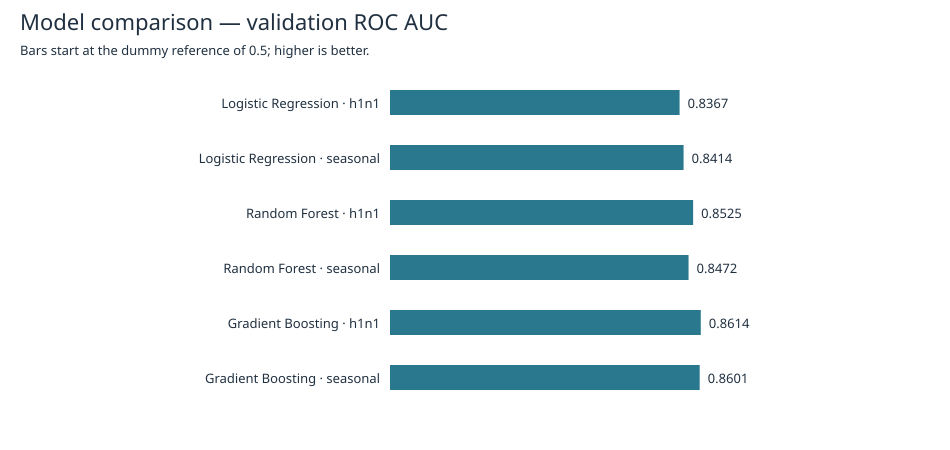

Saved experiment reports to: /Users/zahra.nourbakhsh/Downloads/ReDI/Vaccine_Prediction_Team_5/Vaccine_Prediction_Team_5/reports/modeling
Best validation mean AUC in this comparison: Gradient Boosting
Next: interpret stable feature groups across models; compare baseline versus engineered features before making claims about their benefit.


In [9]:
from html import escape

def show_comparison_chart():
    rows = results[['model', 'target', 'roc_auc', 'cv_roc_auc_mean']]
    width, height = 950, 120+len(rows)*55
    pieces = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
              '<rect width="100%" height="100%" fill="white"/><g font-family="sans-serif" fill="#203040">',
              '<text x="20" y="30" font-size="22">Model comparison — validation ROC AUC</text>',
              '<text x="20" y="55" font-size="13">Bars start at the dummy reference of 0.5; higher is better.</text>']
    for i, (_, row) in enumerate(rows.iterrows()):
        y = 90+i*55
        x, length = 390, max(0, (row.roc_auc-.5)/.5*430)
        label = f'{row.model} · {row.target.replace("_vaccine", "")}'
        pieces.append(f'<text x="380" y="{y+18}" text-anchor="end" font-size="13">{escape(label)}</text><rect x="{x}" y="{y}" width="{length}" height="25" fill="#2a788e"/><text x="{x+length+8}" y="{y+18}" font-size="13">{row.roc_auc:.4f}</text>')
    pieces.append('</g></svg>')
    svg = ''.join(pieces)
    (OUT/'model_comparison.svg').write_text(svg)
    if SVG is not None:
        display(SVG(data=svg))
    return svg

model_comparison_svg = show_comparison_chart()
# Tables are combined by record type to avoid one report file per check/model.
metric_export = pd.concat([results.assign(record_type='validation'),
                          fold_results.assign(record_type='cross_validation'),
                          subgroup_results.assign(record_type='validation_subgroup'),
                          pd.DataFrame(dummy_rows).assign(record_type='dummy')], ignore_index=True)
metric_export.to_csv(OUT/'model_results.csv', index=False)
predictions.to_csv(OUT/'validation_predictions.csv', index=False)
importance.to_csv(OUT/'grouped_permutation_importance.csv', index=False)
coefficient_importance.to_csv(OUT/'native_feature_importance.csv', index=False)

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

experiment = {
    'started_utc': RUN_STARTED, 'completed_utc': datetime.now(timezone.utc).isoformat(),
    'seed': SEED, 'cv_folds': CV_FOLDS, 'permutation_repeats': PERMUTATION_REPEATS,
    'versions': {'python': platform.python_version(), 'numpy': np.__version__,
                 'pandas': pd.__version__, 'sklearn': sklearn.__version__},
    'rows': {'training': len(X_train), 'validation': len(X_validation)},
    'targets': TARGETS, 'feature_columns': feature_state['feature_columns'],
    'models': {name: model.get_params(deep=False) for name, model in MODELS.items()},
    'feature_groups': FEATURE_GROUPS,
    'cv_validation_respondent_ids': [prepared_train.iloc[v].respondent_id.tolist() for _, v in cv_splits],
    'source_hashes': {str(path.relative_to(ROOT)): sha256(path) for path in [
        ROOT/'data_sets/training_set_features.csv', ROOT/'data_sets/training_set_labels.csv',
        ROOT/'data_processed/ml_features/train.csv', ROOT/'data_processed/ml_features/validation.csv',
        ROOT/'data_processed/ml_features/preprocessing_state.json']},
    'preprocessing_definition': feature_state,
    'cv_preprocessing': 'SurveyFeatures fitted separately within each fold. No pre-encoded CV input.',
    'limits': ['Validation is development data after feature exploration, not a fresh final test.',
               'Importance is model-dependent association, not causation.',
               'Correlated predictors share importance; scores/flags should be interpreted together.',
               'Threshold metrics use 0.5 without optimization.',
               'CV covers filtered training respondents; validation also includes high-unknown respondents.'],
    'comparison': comparison.reset_index().to_dict(orient='records'),
}
from importlib.metadata import version
experiment['versions'].update({name: version(name) for name in ['scipy', 'joblib', 'threadpoolctl']})
notebook_cells = json.loads((ROOT/'notebook/05_models_and_interpretation.ipynb').read_text())['cells']
experiment['notebook_code_sha256'] = hashlib.sha256(''.join(''.join(c['source']) for c in notebook_cells if c['cell_type']=='code').encode()).hexdigest()
(OUT/'experiment.json').write_text(json.dumps(experiment, indent=2, default=str)+'\n')
print('Saved experiment reports to:', OUT)
print('Best validation mean AUC in this comparison:', comparison.index[0])
print('Next: interpret stable feature groups across models; compare baseline versus engineered features before making claims about their benefit.')


## 9. What the models agree on

Compare feature groups across all three model families, rather than declaring importance from one coefficient or one forest. The chart shows validation ROC AUC lost when each source group is shuffled. The following summary is generated from the saved results. Its conclusions are descriptive and model-dependent; they do not establish causes or prove a feature-engineering choice improves performance.


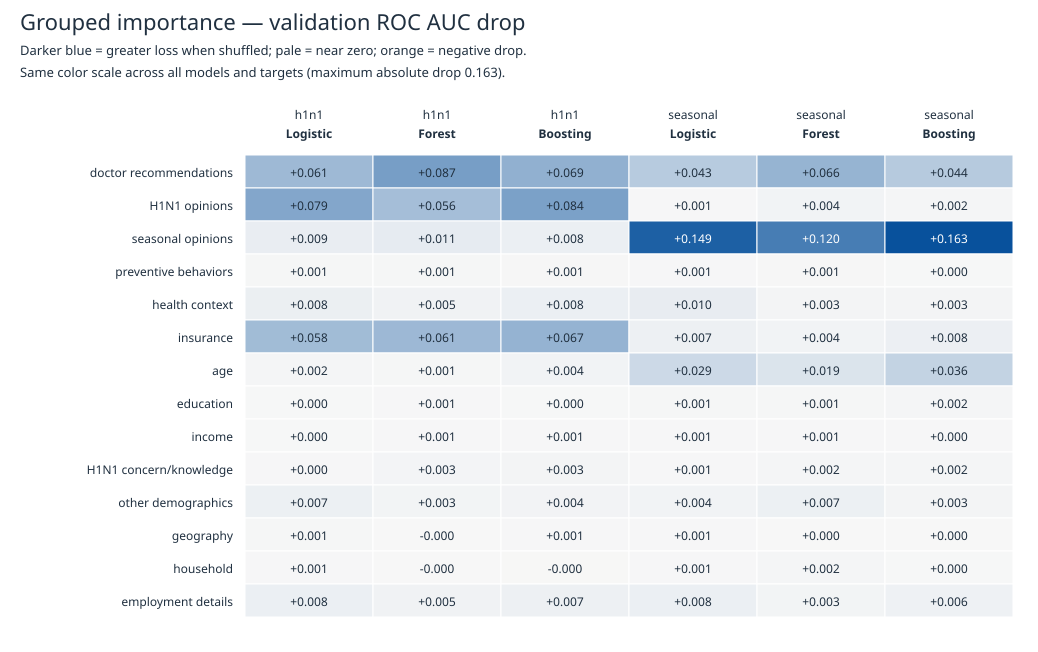

h1n1_vaccine: highest validation ROC AUC is 0.8614 (Gradient Boosting); CV mean 0.8744.
Feature groups in the top three for all models: H1N1 opinions, doctor recommendations, insurance
seasonal_vaccine: highest validation ROC AUC is 0.8601 (Gradient Boosting); CV mean 0.8657.
Feature groups in the top three for all models: seasonal opinions, doctor recommendations, age
Insurance importance includes the informative unknown-insurance pattern; it is not an estimate of a causal insurance benefit.
Prevention and health summaries are candidate predictors; this experiment does not compare them against a non-engineered baseline.
Recommendation-missing subgroup results are based on 433 validation respondents, so avoid treating their rankings as precise population estimates.


In [10]:
# Two target blocks, each with the same three model columns and color scale.
model_order = ['Logistic Regression', 'Random Forest', 'Gradient Boosting']
group_order = list(FEATURE_GROUPS)
importance_matrix = pd.DataFrame(index=group_order)
for target in TARGETS:
    for model in model_order:
        part = importance.loc[importance.target.eq(target) & importance.model.eq(model)].set_index('feature_group')
        importance_matrix[f'{target}|{model}'] = part['auc_drop_mean'].reindex(group_order)
assert importance_matrix.notna().all().all()
row_height, col_width, left, top = 33, 128, 245, 155
width, height = left+6*col_width+25, top+len(group_order)*row_height+35
limit = max(.01, float(np.abs(importance_matrix.to_numpy()).max()))
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}" role="img" aria-label="Grouped feature importance by model and vaccination target">',
         '<rect width="100%" height="100%" fill="white"/><g font-family="sans-serif" fill="#203040">',
         '<text x="20" y="30" font-size="22">Grouped importance — validation ROC AUC drop</text>',
         '<text x="20" y="55" font-size="13">Darker blue = greater loss when shuffled; pale = near zero; orange = negative drop.</text>',
         f'<text x="20" y="77" font-size="13">Same color scale across all models and targets (maximum absolute drop {limit:.3f}).</text>']
short_model = {'Logistic Regression': 'Logistic', 'Random Forest': 'Forest', 'Gradient Boosting': 'Boosting'}
for j, name in enumerate(importance_matrix.columns):
    target, model = name.split('|')
    x = left+j*col_width+col_width/2
    parts.append(f'<text x="{x}" y="{top-36}" text-anchor="middle" font-size="12">{target.replace("_vaccine", "")}</text><text x="{x}" y="{top-17}" text-anchor="middle" font-size="12" font-weight="bold">{short_model[model]}</text>')
for i, group in enumerate(group_order):
    y = top+i*row_height
    parts.append(f'<text x="{left-12}" y="{y+22}" text-anchor="end" font-size="12">{escape(group)}</text>')
    for j, name in enumerate(importance_matrix.columns):
        value = float(importance_matrix.loc[group, name])
        end = (8,81,156) if value >= 0 else (217,95,14)
        color = '#'+''.join(f'{round(247+(v-247)*min(abs(value)/limit,1)):02x}' for v in end)
        ink = 'white' if abs(value)/limit > .6 else '#203040'
        x = left+j*col_width
        parts.append(f'<g><title>{escape(group+" | "+name)}: AUC drop={value:.5f}</title><rect x="{x}" y="{y}" width="{col_width}" height="{row_height}" fill="{color}" stroke="white"/><text x="{x+col_width/2}" y="{y+22}" text-anchor="middle" font-size="12" fill="{ink}">{value:+.3f}</text></g>')
parts.append('</g></svg>')
importance_comparison_svg = ''.join(parts)
(OUT/'grouped_importance_comparison.svg').write_text(importance_comparison_svg)
if SVG is not None:
    display(SVG(data=importance_comparison_svg))

for target in TARGETS:
    target_rows = results.loc[results.target.eq(target)]
    best = target_rows.loc[target_rows.roc_auc.idxmax()]
    print(f'{target}: highest validation ROC AUC is {best.roc_auc:.4f} ({best.model}); CV mean {best.cv_roc_auc_mean:.4f}.')
    top_groups = []
    for model in model_order:
        top = importance.loc[importance.target.eq(target) & importance.model.eq(model)].nlargest(3, 'auc_drop_mean')
        top_groups.extend(top.feature_group.tolist())
    agreement = pd.Series(top_groups).value_counts()
    shared = agreement[agreement.eq(len(model_order))].index.tolist()
    print('Feature groups in the top three for all models:', ', '.join(shared) or 'none')
print('Insurance importance includes the informative unknown-insurance pattern; it is not an estimate of a causal insurance benefit.')
print('Prevention and health summaries are candidate predictors; this experiment does not compare them against a non-engineered baseline.')
print('Recommendation-missing subgroup results are based on 433 validation respondents, so avoid treating their rankings as precise population estimates.')


## Reading the results

1. Compare all models with the dummy and inspect CV spread and training–validation gaps.
2. Compare the two targets: age may matter differently for seasonal and H1N1 uptake; doctor recommendations and vaccine-specific beliefs need separate interpretation.
3. Use grouped permutation importance for cross-model comparisons. Read raw coefficient direction only after considering correlated inputs and missing flags.
4. Inspect respondents with missing doctor recommendations; they were retained deliberately.
5. Do not drop features or claim engineered scores help solely from these charts. A subsequent controlled comparison can test baseline versus engineered inputs on the same folds.

References: [scikit-learn pipelines and leakage](https://scikit-learn.org/stable/common_pitfalls.html), [cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html), [permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).
